In [1]:
# VS Code / local Windows dataset configuration
from pathlib import Path
import os
import random
import numpy as np

PROJECT_ROOT = Path.cwd()
# Supports running the notebook with either the repo root or this folder as cwd.
if (PROJECT_ROOT / "Disease prediction").is_dir():
    DISEASE_DIR = PROJECT_ROOT / "Disease prediction"
elif PROJECT_ROOT.name.lower() == "disease prediction":
    DISEASE_DIR = PROJECT_ROOT
else:
    raise FileNotFoundError(
        f"Could not find 'Disease prediction' from {PROJECT_ROOT}. Open the AgriTech project folder in VS Code."
    )

DATASET_DIR = DISEASE_DIR / "tomato disease detection" / "Dataset"
if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Tomato dataset folder was not found: {DATASET_DIR}")

# This project dataset is arranged as Dataset/Class_Name/image files.
# We create a reproducible 80/20 train/validation split below; no Kaggle paths needed.
train_dir = DATASET_DIR
valid_dir = DATASET_DIR
test_dir = None
Diseases_classes = sorted(path.name for path in DATASET_DIR.iterdir() if path.is_dir())
if not Diseases_classes:
    raise FileNotFoundError(f"No class subfolders found inside {DATASET_DIR}")

print(f"Dataset: {DATASET_DIR}")
print(f"Classes ({len(Diseases_classes)}):")
print("\n".join(Diseases_classes))
print("\nValidation set: reproducible 20% split from the project dataset")


Dataset: c:\Users\KIIT0001\OneDrive\Desktop\AgriTech\Disease prediction\tomato disease detection\Dataset
Classes (10):
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy

Validation set: reproducible 20% split from the project dataset


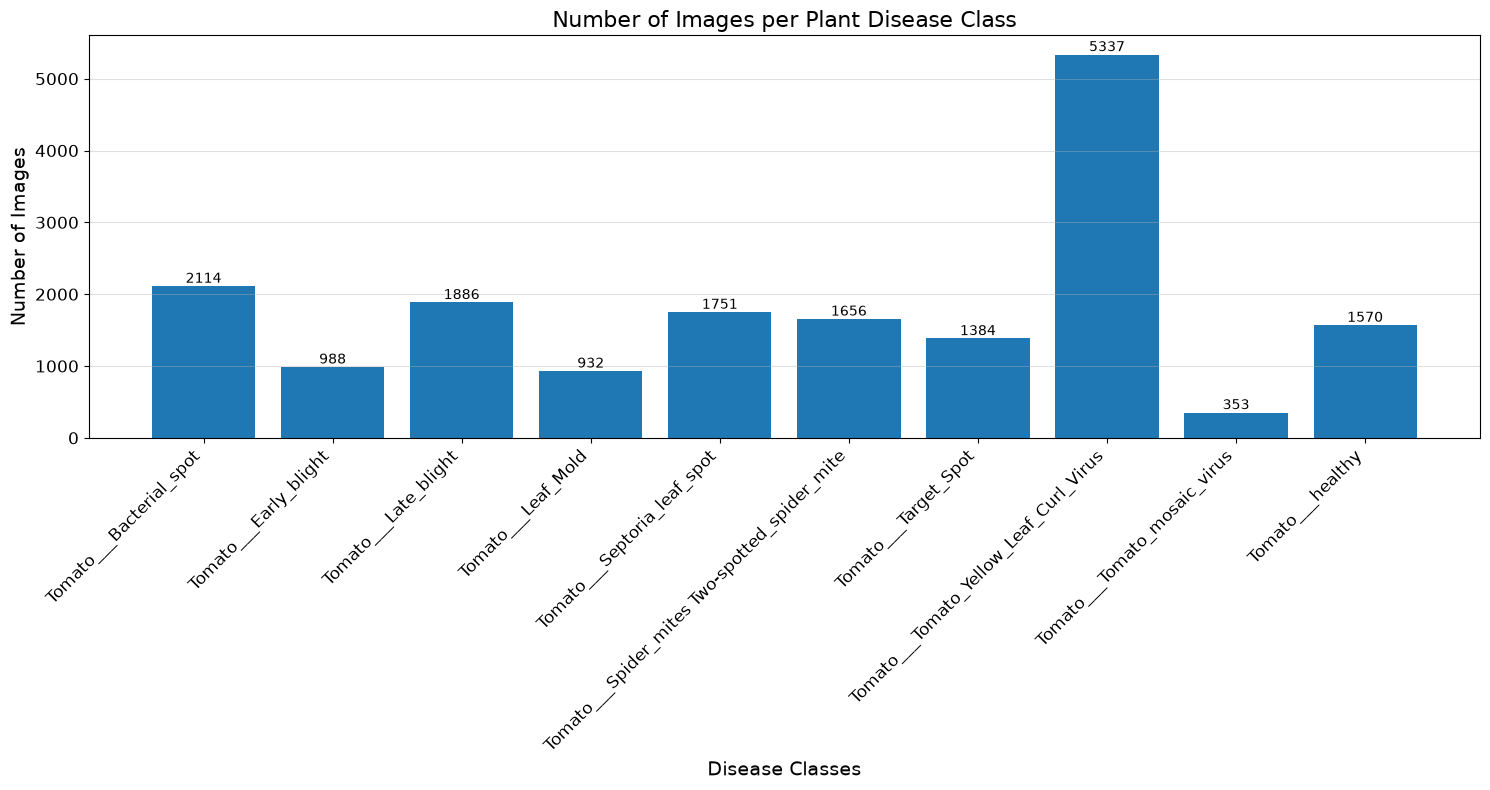


Image Count Summary:
Tomato___Bacterial_spot       :  2114 images
Tomato___Early_blight         :   988 images
Tomato___Late_blight          :  1886 images
Tomato___Leaf_Mold            :   932 images
Tomato___Septoria_leaf_spot   :  1751 images
Tomato___Spider_mites Two-spotted_spider_mite:  1656 images
Tomato___Target_Spot          :  1384 images
Tomato___Tomato_Yellow_Leaf_Curl_Virus:  5337 images
Tomato___Tomato_mosaic_virus  :   353 images
Tomato___healthy              :  1570 images

Total images: 17971


In [2]:
import matplotlib.pyplot as plt 
import os  
from colorama import Fore, Style 

label_counts = {}  
for label in Diseases_classes:
    image_paths = os.listdir(os.path.join(train_dir, label))  
    label_counts[label] = len(image_paths)  

plt.figure(figsize=(15, 8))  
bars = plt.bar(label_counts.keys(), label_counts.values())

plt.title('Number of Images per Plant Disease Class', fontsize=16)  
plt.xlabel('Disease Classes', fontsize=14)  
plt.ylabel('Number of Images', fontsize=14)  
plt.xticks(rotation=45, ha='right', fontsize=12)  
plt.yticks(fontsize=12)  
plt.grid(axis='y', alpha=0.4) 
for bar in bars:
    height = bar.get_height()  
    plt.text(bar.get_x() + bar.get_width()/2., height,  
             f'{int(height)}', 
             ha='center', va='bottom', fontsize=10) 

plt.tight_layout() 
plt.show()  

print(Fore.GREEN + "\nImage Count Summary:")  
for label, count in label_counts.items():
    print(f"{label:<30}: {count:>5} images")  
print(Style.RESET_ALL + f"\nTotal images: {sum(label_counts.values())}")


In [3]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split, Subset
from PIL import Image
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import torch.optim as optim
import torch.nn.functional as F

# The backend uses the same 256x256 RGB tensor preprocessing.
image_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])
full_dataset = ImageFolder(str(DATASET_DIR), transform=image_transform)
if full_dataset.classes != Diseases_classes:
    raise RuntimeError("Dataset class order changed while loading; stop to avoid incorrect labels.")

# Use a fixed seed so validation membership stays stable across runs.
validation_size = max(1, int(0.2 * len(full_dataset)))
training_size = len(full_dataset) - validation_size
train_subset, valid_subset = random_split(
    full_dataset,
    [training_size, validation_size],
    generator=torch.Generator().manual_seed(42),
)
# Keep `train.classes` compatible with the notebook's plotting/export cells.
train = full_dataset
valid = full_dataset
print(f"Images: {len(full_dataset)} | train: {len(train_subset)} | validation: {len(valid_subset)}")


Images: 17971 | train: 14377 | validation: 3594


In [4]:
train[0]

(tensor([[[0.6314, 0.6314, 0.6314,  ..., 0.5686, 0.5686, 0.5686],
          [0.6314, 0.6314, 0.6314,  ..., 0.5686, 0.5686, 0.5686],
          [0.6314, 0.6314, 0.6314,  ..., 0.5725, 0.5725, 0.5725],
          ...,
          [0.4235, 0.4235, 0.4314,  ..., 0.4510, 0.4510, 0.4510],
          [0.4196, 0.4235, 0.4314,  ..., 0.4510, 0.4510, 0.4510],
          [0.4196, 0.4235, 0.4314,  ..., 0.4510, 0.4510, 0.4510]],
 
         [[0.6314, 0.6314, 0.6314,  ..., 0.5608, 0.5608, 0.5608],
          [0.6314, 0.6314, 0.6314,  ..., 0.5608, 0.5608, 0.5608],
          [0.6314, 0.6314, 0.6314,  ..., 0.5647, 0.5647, 0.5647],
          ...,
          [0.4000, 0.4000, 0.4078,  ..., 0.4275, 0.4275, 0.4275],
          [0.3961, 0.4000, 0.4078,  ..., 0.4275, 0.4275, 0.4275],
          [0.3961, 0.4000, 0.4078,  ..., 0.4275, 0.4275, 0.4275]],
 
         [[0.6235, 0.6235, 0.6235,  ..., 0.5647, 0.5647, 0.5647],
          [0.6235, 0.6235, 0.6235,  ..., 0.5647, 0.5647, 0.5647],
          [0.6235, 0.6235, 0.6235,  ...,

Dataset ImageFolder
    Number of datapoints: 17971
    Root location: c:\Users\KIIT0001\OneDrive\Desktop\AgriTech\Disease prediction\tomato disease detection\Dataset
    StandardTransform
Transform: Compose(
               Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )
torch.Size([3, 256, 256]) 0
Label: Tomato___Bacterial_spot (0)
Label: Tomato___Early_blight (1)
Label: Tomato___Leaf_Mold (3)
Label: Tomato___Spider_mites Two-spotted_spider_mite (5)
Label: Tomato___Target_Spot (6)
Label: Tomato___Tomato_Yellow_Leaf_Curl_Virus (7)
Label: Tomato___Tomato_Yellow_Leaf_Curl_Virus (7)
Label: Tomato___healthy (9)


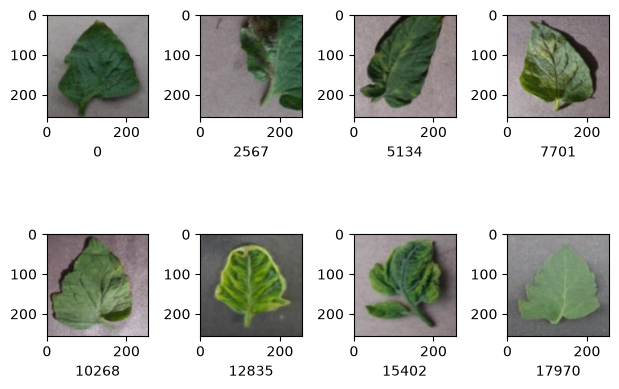

In [5]:
print(train)

img, label = train[0]
print(img.shape, label)

def show_image(image, label):
    print("Label: " + train.classes[label] + " (" + str(label) + ")")
    plt.imshow(image.permute(1, 2, 0))

# Display up to eight real samples; the project dataset is smaller than the Kaggle dataset.
image_list = np.linspace(0, len(train) - 1, min(8, len(train)), dtype=int)
for plot_index, sample_index in enumerate(image_list, start=1):
    plt.subplot(2, 4, plot_index)
    plt.tight_layout()
    plt.xlabel(sample_index, fontsize=10)
    show_image(*train[int(sample_index)])
plt.show()


In [6]:
batch_size = 16  # modest batch size works better on a typical Windows laptop
num_workers = 0  # safest setting for Windows/Jupyter
pin_memory = torch.cuda.is_available()

train_dataloader = DataLoader(train_subset, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=pin_memory)
valid_dataloader = DataLoader(valid_subset, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, pin_memory=pin_memory)

def get_default_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

def to_device(data, device):
    if isinstance(data, (list, tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True)

class DeviceDataLoader:
    def __init__(self, dataloader, device):
        self.dataloader = dataloader
        self.device = device
    def __iter__(self):
        for batch in self.dataloader:
            yield to_device(batch, self.device)
    def __len__(self):
        return len(self.dataloader)

device = get_default_device()
train_dataloader = DeviceDataLoader(train_dataloader, device)
valid_dataloader = DeviceDataLoader(valid_dataloader, device)
print(f"Training on {device}")

def accuracy(outputs, labels):
    _, preds = torch.max(outputs, dim=1)
    return torch.tensor(torch.sum(preds == labels).item() / len(preds))

class ImageClassificationBase(nn.Module):
    def training_step(self, batch):
        images, labels = batch
        return F.cross_entropy(self(images), labels)
    def validation_step(self, batch):
        images, labels = batch
        out = self(images)
        return {'val_loss': F.cross_entropy(out, labels).detach(), 'val_acc': accuracy(out, labels)}
    def validation_epoch_end(self, outputs):
        return {'val_loss': torch.stack([x['val_loss'] for x in outputs]).mean().item(),
                'val_acc': torch.stack([x['val_acc'] for x in outputs]).mean().item()}
    def epoch_end(self, epoch, result):
        print("Epoch [{}], train_loss: {:.4f}, val_loss: {:.4f}, val_acc: {:.4f}".format(
            epoch + 1, result['train_loss'], result['val_loss'], result['val_acc']))

def ConvBlock(in_channels, out_channels, pool=False):
    layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
              nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True)]
    if pool:
        layers.append(nn.MaxPool2d(4))
    return nn.Sequential(*layers)

class CNN_NeuralNet(ImageClassificationBase):
    def __init__(self, in_channels, num_diseases):
        super().__init__()
        self.conv1 = ConvBlock(in_channels, 64)
        self.conv2 = ConvBlock(64, 128, pool=True)
        self.res1 = nn.Sequential(ConvBlock(128, 128), ConvBlock(128, 128))
        self.conv3 = ConvBlock(128, 256, pool=True)
        self.conv4 = ConvBlock(256, 512, pool=True)
        self.res2 = nn.Sequential(ConvBlock(512, 512), ConvBlock(512, 512))
        self.classifier = nn.Sequential(nn.MaxPool2d(4), nn.Flatten(), nn.Linear(512, num_diseases))
    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.res1(out) + out
        out = self.conv3(out)
        out = self.conv4(out)
        out = self.res2(out) + out
        return self.classifier(out)

model = to_device(CNN_NeuralNet(3, len(train.classes)), device)
print(model)


Training on cpu
CNN_NeuralNet(
  (conv1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  )
  (res1): Sequential(
    (0): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=Tru

In [7]:
@torch.no_grad()
def evaluate(model, val_loader):
    model.eval()
    outputs = [model.validation_step(batch) for batch in val_loader]
    return model.validation_epoch_end(outputs)


In [8]:
def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']

def fit_OneCycle(epochs, max_lr, model, train_loader, val_loader, weight_decay=0,
                grad_clip=None, opt_func=torch.optim.SGD):
    torch.cuda.empty_cache()
    history = []  
    
    optimizer = opt_func(model.parameters(), max_lr, weight_decay=weight_decay)
    
    sched = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr,
                                                epochs=epochs, steps_per_epoch=len(train_loader))
    
    for epoch in range(epochs):
        model.train()
        train_losses = []
        lrs = []
        for batch in train_loader:
            loss = model.training_step(batch)
            train_losses.append(loss)
            loss.backward()
            
            if grad_clip: 
                nn.utils.clip_grad_value_(model.parameters(), grad_clip)
                
            optimizer.step()
            optimizer.zero_grad()

            lrs.append(get_lr(optimizer))
            sched.step()
        result = evaluate(model, val_loader)
        result['train_loss'] = torch.stack(train_losses).mean().item()
        result['lrs'] = lrs
        model.epoch_end(epoch, result)
        history.append(result)
        
    return history


In [9]:
num_epoch = 5          
lr_rate = 0.01         
grad_clip = 0.15       
weight_decay = 1e-4    
optims = torch.optim.Adam  
history = [evaluate(model, valid_dataloader)]
history += fit_OneCycle(
    num_epoch, lr_rate, model, train_dataloader, valid_dataloader, 
    grad_clip=grad_clip, 
    weight_decay=weight_decay, 
    opt_func=optims
)


Epoch [1], train_loss: 0.9453, val_loss: 1.3816, val_acc: 0.6253
Epoch [2], train_loss: 0.6239, val_loss: 0.5435, val_acc: 0.8287
Epoch [3], train_loss: 0.3925, val_loss: 0.8145, val_acc: 0.7562
Epoch [4], train_loss: 0.2347, val_loss: 0.1562, val_acc: 0.9426
Epoch [5], train_loss: 0.0805, val_loss: 0.0596, val_acc: 0.9794


C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_13252\3154855987.py:10: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r--" (-> color='r'). The keyword argument will take precedence.
  plt.plot(epoch_count, train_loss, 'r--', color='orangered', label='Training Loss')
C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_13252\3154855987.py:11: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "--bo" (-> color='b'). The keyword argument will take precedence.
  plt.plot(epoch_count, val_loss, '--bo', color='green', linewidth=2.5, label='Validation Loss')


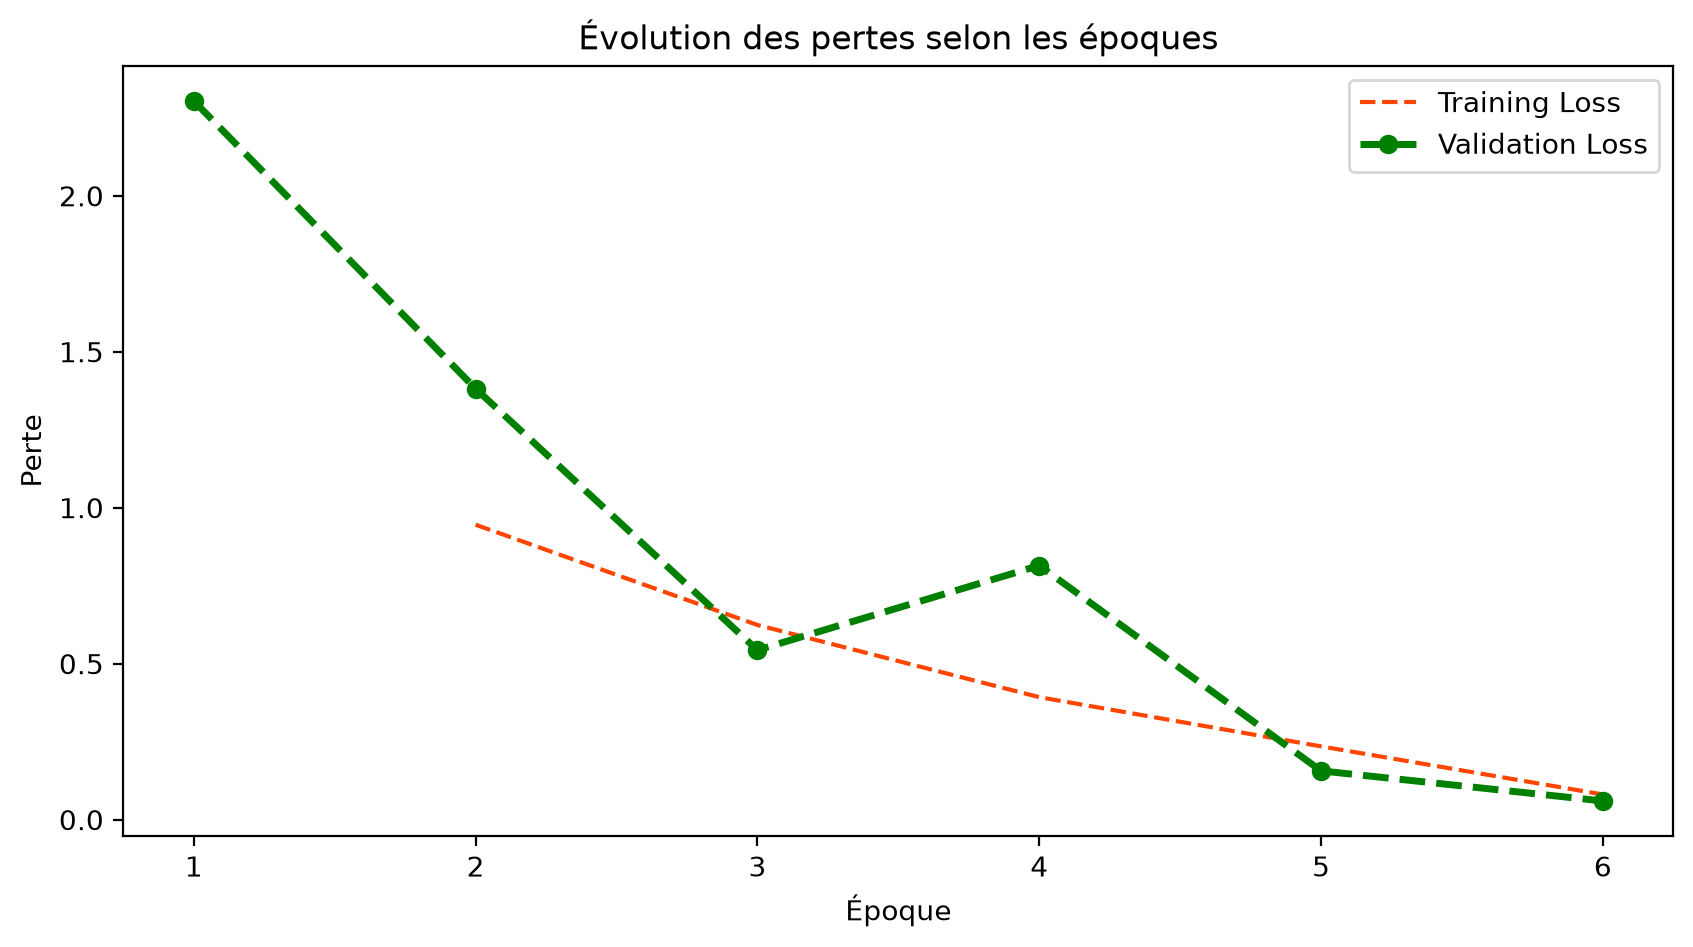

C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_13252\3154855987.py:19: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "--bo" (-> color='b'). The keyword argument will take precedence.
  plt.plot(epoch_count, val_acc, '--bo', color='green', linewidth=2.5, label='Validation Accuracy')


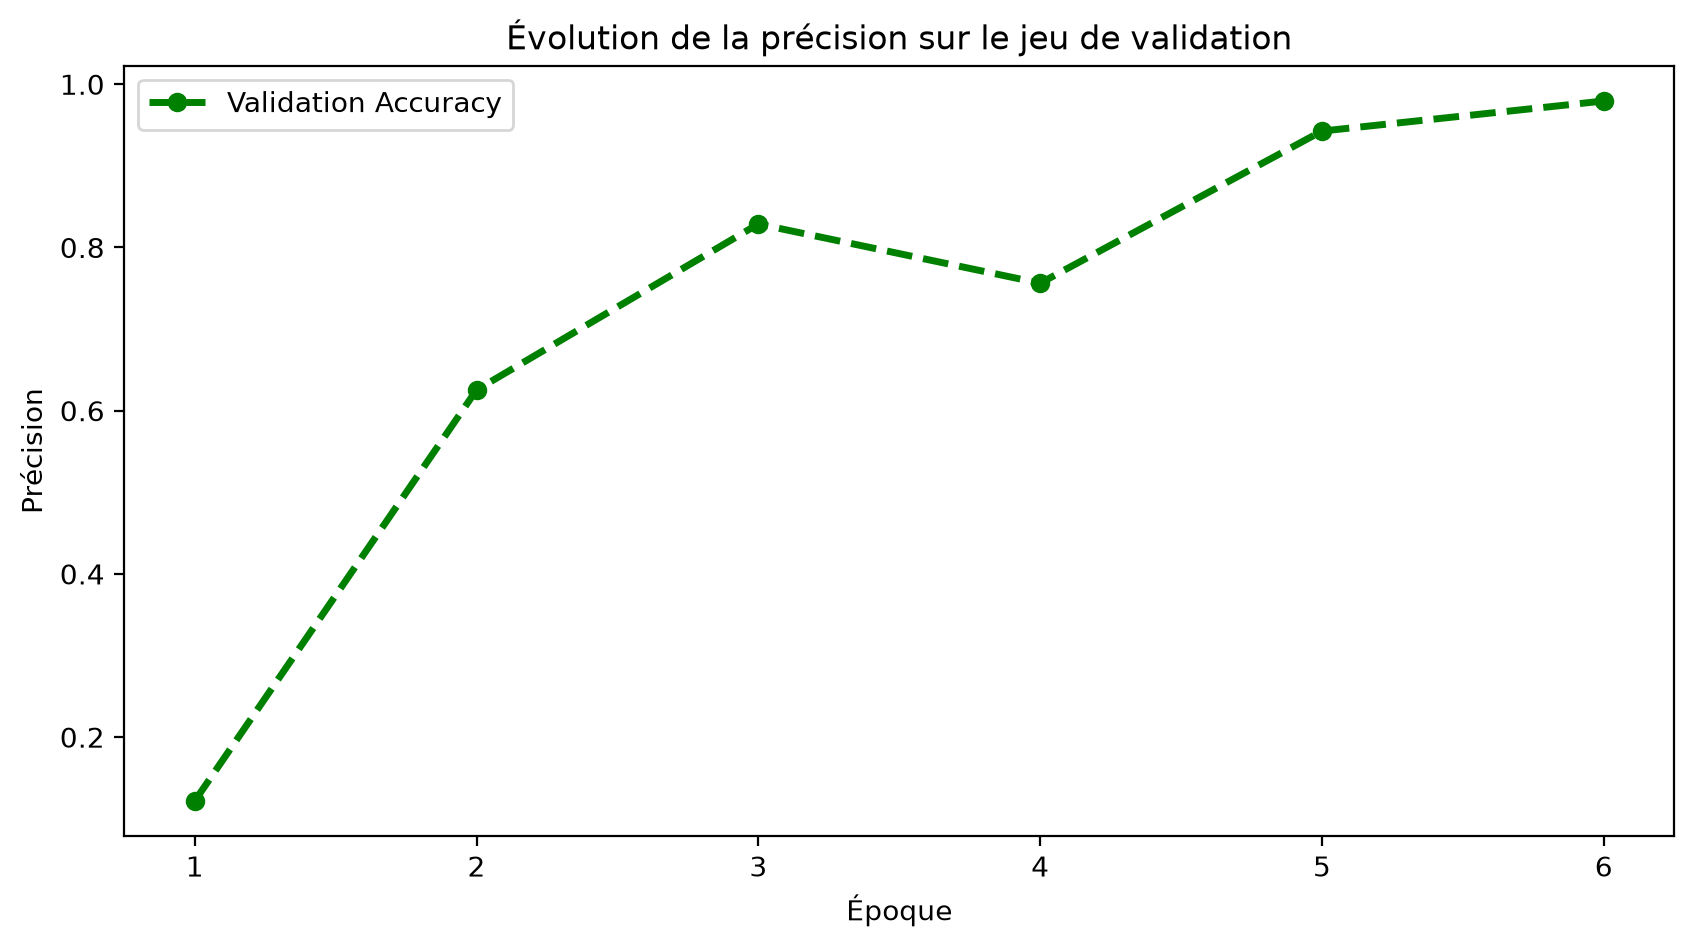

In [10]:
val_acc = []    
val_loss = []   
train_loss = [] 
for i in history:
    val_acc.append(i['val_acc'])
    val_loss.append(i['val_loss'])
    train_loss.append(i.get('train_loss'))
epoch_count = range(1, 7)
plt.figure(figsize=(10,5), dpi=200)
plt.plot(epoch_count, train_loss, 'r--', color='orangered', label='Training Loss')
plt.plot(epoch_count, val_loss, '--bo', color='green', linewidth=2.5, label='Validation Loss')
plt.legend()
plt.title('Évolution des pertes selon les époques')
plt.xlabel('Époque')
plt.ylabel('Perte')
plt.xticks(np.arange(1,7,1))
plt.show()
plt.figure(figsize=(10,5), dpi=200)
plt.plot(epoch_count, val_acc, '--bo', color='green', linewidth=2.5, label='Validation Accuracy')
plt.legend()
plt.title('Évolution de la précision sur le jeu de validation')
plt.xlabel('Époque')
plt.ylabel('Précision')
plt.xticks(np.arange(1,7,1))
plt.show()

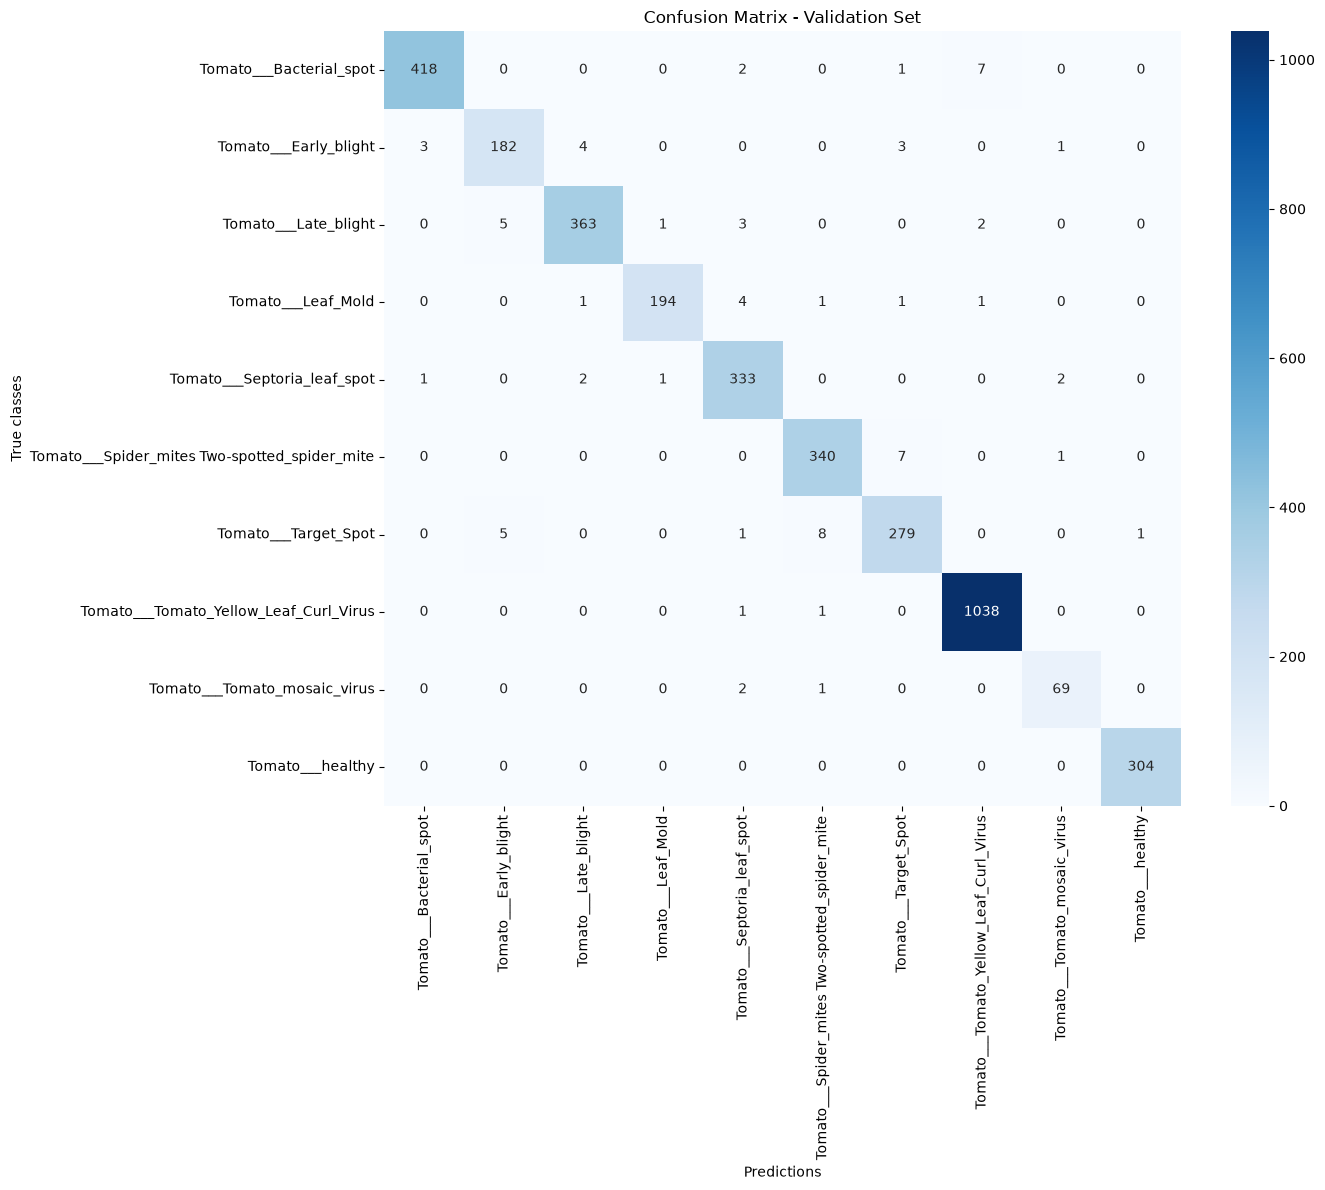

=== Classification Report ===
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.99      0.98      0.98       428
                        Tomato___Early_blight       0.95      0.94      0.95       193
                         Tomato___Late_blight       0.98      0.97      0.98       374
                           Tomato___Leaf_Mold       0.99      0.96      0.97       202
                  Tomato___Septoria_leaf_spot       0.96      0.98      0.97       339
Tomato___Spider_mites Two-spotted_spider_mite       0.97      0.98      0.97       348
                         Tomato___Target_Spot       0.96      0.95      0.95       294
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.99      1.00      0.99      1040
                 Tomato___Tomato_mosaic_virus       0.95      0.96      0.95        72
                             Tomato___healthy       1.00      1.00      1.00       304

           

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()
all_labels = []
all_preds = []
with torch.no_grad():
    for images, labels in valid_dataloader:
        outputs = model(images)
        predicted = outputs.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train.classes, yticklabels=train.classes)
plt.title("Confusion Matrix - Validation Set")
plt.xlabel("Predictions")
plt.ylabel("True classes")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
print("=== Classification Report ===")
print(classification_report(all_labels, all_preds, target_names=train.classes, zero_division=0))


In [12]:
# Save directly beside the backend's expected checkpoint location.
import json
output_dir = DISEASE_DIR
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = output_dir / "plant_disease_model.pth"
classes_path = output_dir / "plant_disease_classes.json"
torch.save(model.state_dict(), checkpoint_path)
with classes_path.open("w", encoding="utf-8") as class_file:
    json.dump(train.classes, class_file, ensure_ascii=False, indent=2)
print(f"Saved model: {checkpoint_path}")
print(f"Saved classes: {classes_path}")


Saved model: c:\Users\KIIT0001\OneDrive\Desktop\AgriTech\Disease prediction\plant_disease_model.pth
Saved classes: c:\Users\KIIT0001\OneDrive\Desktop\AgriTech\Disease prediction\plant_disease_classes.json


In [13]:
from IPython.display import FileLink, display
display(FileLink(str(checkpoint_path)))
display(FileLink(str(classes_path)))


c:\Users\KIIT0001\OneDrive\Desktop\AgriTech\Disease prediction\plant_disease_model.pth

c:\Users\KIIT0001\OneDrive\Desktop\AgriTech\Disease prediction\plant_disease_classes.json